# Support Vector Machine (SVM) — Clasificador

**Repositorio:** `autodidact/both/svm/`

---

## 1. Idea General e Intuición

SVM busca el **hiperplano de máximo margen** que separa las clases. No cualquier hiperplano que separe los datos, sino el que maximiza la distancia entre el hiperplano y los puntos más cercanos de cada clase (los **vectores de soporte**).

**Intuición:** Imagina dos grupos de puntos en un plano. Hay infinitos hiperplanos que los separan. SVM elige el que está "más alejado" de ambos grupos — el más robusto ante nuevos datos.

**Caso no lineal:** Mediante el **truco del kernel**, SVM proyecta los datos a un espacio de mayor dimensión donde sí son separables linealmente, sin calcular explícitamente esa proyección.

## 2. Fundamento Matemático

### 2.1 Hiperplano y Margen (Caso Linealmente Separable)

Un hiperplano en $\mathbb{R}^d$: $\mathbf{w}^\top \mathbf{x} + b = 0$

Las clases se definen como $y_i \in \{-1, +1\}$ y deben satisfacer:
$$y_i(\mathbf{w}^\top \mathbf{x}_i + b) \geq 1 \quad \forall i$$

El **margen** (distancia entre los dos hiperplanos de soporte) es:
$$\text{Margen} = \frac{2}{\|\mathbf{w}\|}$$

**Maximizar el margen** equivale a **minimizar** $\|\mathbf{w}\|$:

$$\underset{\mathbf{w}, b}{\min} \quad \frac{1}{2}\|\mathbf{w}\|^2 \quad \text{s.t.} \quad y_i(\mathbf{w}^\top \mathbf{x}_i + b) \geq 1$$

### 2.2 Soft-Margin SVM (Caso No Separable — Parámetro C)

Se introducen variables de holgura $\xi_i \geq 0$ para permitir violaciones:

$$\underset{\mathbf{w}, b, \xi}{\min} \quad \frac{1}{2}\|\mathbf{w}\|^2 + C\sum_{i=1}^{n}\xi_i \quad \text{s.t.} \quad y_i(\mathbf{w}^\top \mathbf{x}_i + b) \geq 1 - \xi_i$$

- **C grande:** Penaliza fuertemente los errores → margen pequeño, menos tolerante a violaciones → más sobreajuste.
- **C pequeño:** Tolera más violaciones → margen grande → más regularización.

### 2.3 Formulación Dual y Vectores de Soporte

La solución dual es:

$$\underset{\alpha}{\max} \sum_{i}\alpha_i - \frac{1}{2}\sum_{i,j}\alpha_i\alpha_j y_i y_j \mathbf{x}_i^\top \mathbf{x}_j$$

Solo los puntos con $\alpha_i > 0$ son **vectores de soporte** (los que definen el margen).

La predicción:
$$\hat{y}(\mathbf{x}) = \text{sign}\left(\sum_{i \in SV} \alpha_i y_i \mathbf{x}_i^\top \mathbf{x} + b\right)$$

### 2.4 El Truco del Kernel

Reemplaza el producto interno $\mathbf{x}_i^\top \mathbf{x}_j$ por una función kernel $K(\mathbf{x}_i, \mathbf{x}_j)$:

| Kernel | Fórmula | Uso típico |
|---|---|---|
| **Lineal** | $\mathbf{x}_i^\top \mathbf{x}_j$ | Datos linealmente separables, alta dimensión |
| **RBF (Gaussiano)** | $\exp\!\left(-\gamma\|\mathbf{x}_i - \mathbf{x}_j\|^2\right)$ | Frontera no lineal (default) |
| **Polinomial** | $(\mathbf{x}_i^\top \mathbf{x}_j + r)^d$ | Interacciones polinómicas |
| **Sigmoide** | $\tanh(\gamma\mathbf{x}_i^\top \mathbf{x}_j + r)$ | Redes neuronales |

Para el kernel RBF, $\gamma$ controla el radio de influencia:
- **$\gamma$ grande:** Cada punto de soporte tiene influencia muy local → sobreajuste.
- **$\gamma$ pequeño:** Influencia global, frontera suave.

## 3. ¿Cuándo Usarlo y Cuándo NO?

### ✅ Úsalo cuando:
- El dataset es **pequeño o mediano** (≤ 100k muestras).
- Las clases son **casi linealmente separables** o necesitas kernel RBF.
- Tienes **alta dimensionalidad** y pocas muestras (kernel lineal).
- Necesitas **robustez al ruido** (el margen suave tolera violaciones).

### ❌ NO lo uses cuando:
- Dataset **muy grande** (la complejidad es O(n²)~O(n³) en entrenamiento).
- Necesitas **probabilidades calibradas** (SVM no produce probabilidades directamente).
- El problema requiere **interpretabilidad** de features.
- Muchas features **irrelevantes** (kernel RBF se degrada).

## 4. Métricas de Evaluación

| Métrica | Notas para SVM |
|---|---|
| **Accuracy** | Clases balanceadas |
| **F1-Score** | Clases desbalanceadas; usar `class_weight='balanced'` |
| **ROC-AUC** | Requiere `probability=True` (usa Platt scaling internamente) |
| **Número de SVs** | Diagnóstico: muchos SVs → margen pequeño, posible sobreajuste |

> **Nota:** `predict_proba` en SVC requiere `probability=True`, lo que añade un costo computacional extra mediante validación cruzada interna.

## 5. Problemas y Casos Raros

### 5.1 Sensibilidad al Escalado
SVM usa distancias → features no escaladas dominan el kernel.
**Solución:** `StandardScaler` **siempre**.

### 5.2 Elección de Kernel y Hiperparámetros (C, γ)
El rendimiento es muy sensible a C y γ.
**Solución:** `GridSearchCV` sobre una malla logarítmica de C y γ.

### 5.3 No Escalable a Datasets Grandes
La complejidad es $O(n^2 d)$ en memoria y $O(n^3)$ en tiempo.
**Alternativa:** `LinearSVC` o `SGDClassifier` para datasets grandes.

### 5.4 Clases Desbalanceadas
Los vectores de soporte de la clase minoritaria tienen poco peso.
**Solución:** `class_weight='balanced'`.

### 5.5 Probabilidades No Nativas
`probability=True` usa Platt scaling con CV interna → lento y las probabilidades pueden no estar bien calibradas.

## 6. Mejora de Resultados

| Parámetro | Efecto |
|---|---|
| `C` | Trade-off margen/errores; buscar en $[10^{-3}, 10^{3}]$ |
| `kernel` | `'rbf'` (default), `'linear'`, `'poly'` |
| `gamma` | Solo RBF/poly: `'scale'` (default) o búsqueda en $[10^{-4}, 10^{1}]$ |
| `degree` | Solo kernel poly: grado del polinomio |
| `class_weight` | `'balanced'` para desbalanceo |

**Pipeline recomendado:** `StandardScaler → SVC`

In [1]:
# =============================================================================
# SETUP
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_breast_cancer, load_iris, make_moons, make_circles
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
)

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
SEED = 42
print('✅ Librerías cargadas.')

✅ Librerías cargadas.


---
## 7. Demostración Visual del Margen y Vectores de Soporte

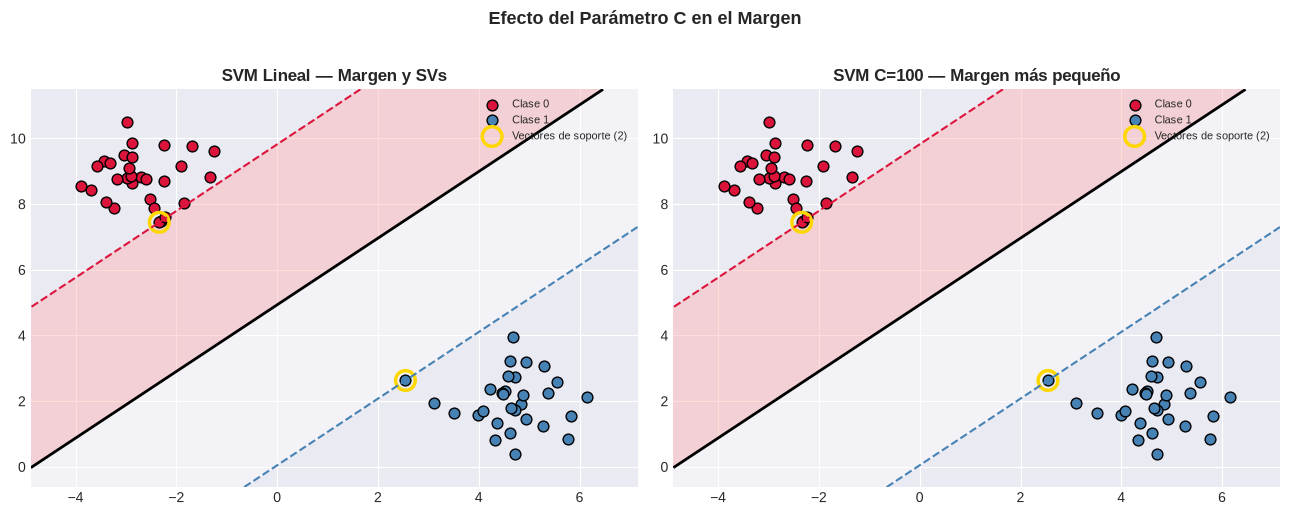

In [2]:
# =============================================================================
# DATOS 2D LINEALMENTE SEPARABLES: visualizar el margen y los vectores de soporte
# =============================================================================
from sklearn.datasets import make_blobs

X_blob, y_blob = make_blobs(n_samples=60, centers=2, cluster_std=0.8, random_state=SEED)

svc_vis = SVC(kernel='linear', C=1.0)
svc_vis.fit(X_blob, y_blob)

def plot_svm_margin(model, X, y, ax, title):
    x0_min, x0_max = X[:,0].min()-1, X[:,0].max()+1
    x1_min, x1_max = X[:,1].min()-1, X[:,1].max()+1
    xx, yy = np.meshgrid(np.linspace(x0_min, x0_max, 300),
                         np.linspace(x1_min, x1_max, 300))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Frontera y márgenes
    ax.contourf(xx, yy, Z, levels=[-1, 0, 1],
                colors=['#FFAAAA','white','#AAAAFF'], alpha=0.4)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1],
               linestyles=['--', '-', '--'],
               colors=['crimson', 'black', 'steelblue'], linewidths=[1.5, 2, 1.5])

    # Puntos
    ax.scatter(X[y==0, 0], X[y==0, 1], color='crimson', edgecolors='k', s=60, label='Clase 0')
    ax.scatter(X[y==1, 0], X[y==1, 1], color='steelblue', edgecolors='k', s=60, label='Clase 1')

    # Vectores de soporte (con círculo)
    ax.scatter(model.support_vectors_[:,0], model.support_vectors_[:,1],
               s=200, facecolors='none', edgecolors='gold', linewidths=2.5,
               label=f'Vectores de soporte ({len(model.support_vectors_)})')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_svm_margin(svc_vis, X_blob, y_blob, axes[0], 'SVM Lineal — Margen y SVs')

# Comparar C pequeño vs C grande
svc_large_C = SVC(kernel='linear', C=100).fit(X_blob, y_blob)
plot_svm_margin(svc_large_C, X_blob, y_blob, axes[1], 'SVM C=100 — Margen más pequeño')

plt.suptitle('Efecto del Parámetro C en el Margen', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 8. Kernels en Datos No Lineales

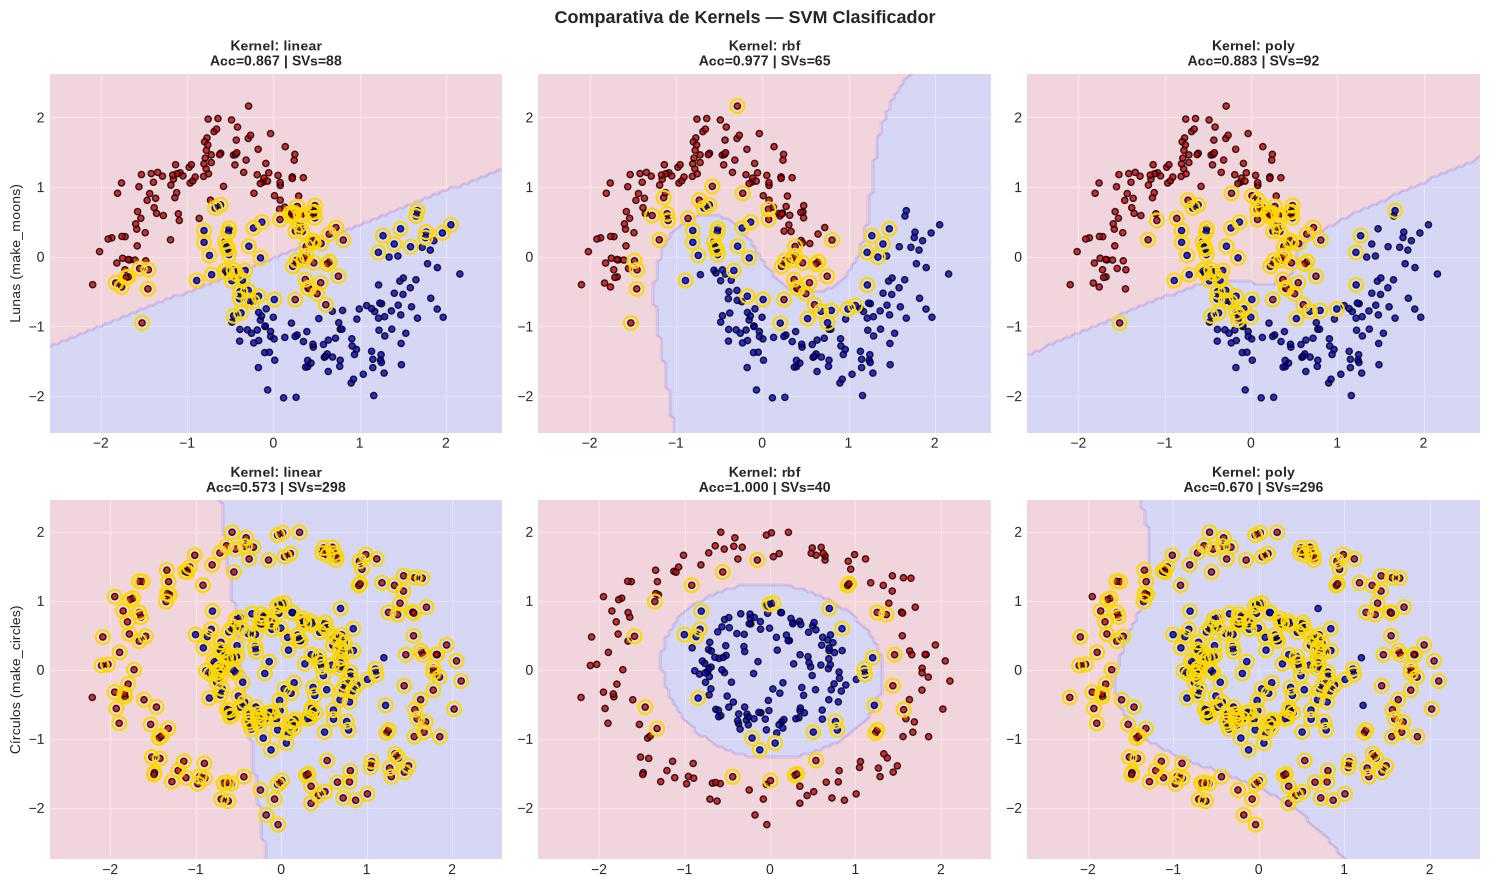

In [3]:
# =============================================================================
# DEMOSTRACIÓN DEL TRUCO DEL KERNEL en datos no linealmente separables
# =============================================================================
datasets = {
    'Lunas (make_moons)':    make_moons(n_samples=300, noise=0.15, random_state=SEED),
    'Círculos (make_circles)': make_circles(n_samples=300, noise=0.1, factor=0.4, random_state=SEED)
}

kernels = [
    ('linear',  {'C': 1.0}),
    ('rbf',     {'C': 1.0, 'gamma': 'scale'}),
    ('poly',    {'C': 1.0, 'degree': 3, 'gamma': 'scale'})
]

cmap_bg  = ListedColormap(['#FFAAAA','#AAAAFF'])
cmap_pts = ListedColormap(['#CC0000','#0000CC'])

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for row, (ds_name, (X_ds, y_ds)) in enumerate(datasets.items()):
    scaler_ds = StandardScaler()
    X_ds_sc   = scaler_ds.fit_transform(X_ds)

    for col, (kernel, kparams) in enumerate(kernels):
        ax = axes[row, col]
        svc_k = SVC(kernel=kernel, probability=False, **kparams)
        svc_k.fit(X_ds_sc, y_ds)
        acc = accuracy_score(y_ds, svc_k.predict(X_ds_sc))

        h = 0.05
        xx, yy = np.meshgrid(np.arange(X_ds_sc[:,0].min()-0.5, X_ds_sc[:,0].max()+0.5, h),
                             np.arange(X_ds_sc[:,1].min()-0.5, X_ds_sc[:,1].max()+0.5, h))
        Z = svc_k.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bg)
        ax.scatter(X_ds_sc[:,0], X_ds_sc[:,1], c=y_ds, cmap=cmap_pts,
                   edgecolors='k', s=20, alpha=0.8)
        ax.scatter(svc_k.support_vectors_[:,0], svc_k.support_vectors_[:,1],
                   s=100, facecolors='none', edgecolors='gold', lw=1.5)
        ax.set_title(f'Kernel: {kernel}\nAcc={acc:.3f} | SVs={len(svc_k.support_vectors_)}',
                     fontsize=10, fontweight='bold')
        if col == 0:
            ax.set_ylabel(ds_name, fontsize=10)

plt.suptitle('Comparativa de Kernels — SVM Clasificador', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 9. Clasificación Real — Breast Cancer

In [4]:
# =============================================================================
# PIPELINE COMPLETO: StandardScaler + SVC
# =============================================================================
bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target

X_tr, X_te, y_tr, y_te = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=SEED, stratify=y_bc
)

pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', C=1.0, gamma='scale',
                probability=True,    # Activa Platt scaling para predict_proba
                class_weight='balanced', random_state=SEED))
])
pipe_svm.fit(X_tr, y_tr)
y_pred_bc  = pipe_svm.predict(X_te)
y_proba_bc = pipe_svm.predict_proba(X_te)[:, 1]

print(f'Accuracy : {accuracy_score(y_te, y_pred_bc):.4f}')
print(f'ROC-AUC  : {roc_auc_score(y_te, y_proba_bc):.4f}')
print(f'SVs      : {pipe_svm.named_steps["svc"].n_support_} (por clase)')
print()
print(classification_report(y_te, y_pred_bc, target_names=bc.target_names))

Accuracy : 0.9649
ROC-AUC  : 0.9940
SVs      : [49 59] (por clase)

              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



In [5]:
# =============================================================================
# GRID SEARCH: Malla logarítmica de C y gamma (la práctica estándar para SVM RBF)
# =============================================================================
param_grid = {
    'svc__C':     [0.01, 0.1, 1, 10, 100],
    'svc__gamma': [0.001, 0.01, 0.1, 1, 'scale']
}

pipe_gs = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', probability=True,
                class_weight='balanced', random_state=SEED))
])

grid = GridSearchCV(pipe_gs, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid.fit(X_tr, y_tr)

print(f'Mejores parámetros : {grid.best_params_}')
print(f'Mejor ROC-AUC (CV) : {grid.best_score_:.4f}')

best_svm = grid.best_estimator_
y_pred_gs  = best_svm.predict(X_te)
y_proba_gs = best_svm.predict_proba(X_te)[:,1]
print(f'Test ROC-AUC       : {roc_auc_score(y_te, y_proba_gs):.4f}')

Mejores parámetros : {'svc__C': 10, 'svc__gamma': 'scale'}
Mejor ROC-AUC (CV) : 0.9948
Test ROC-AUC       : 0.9950


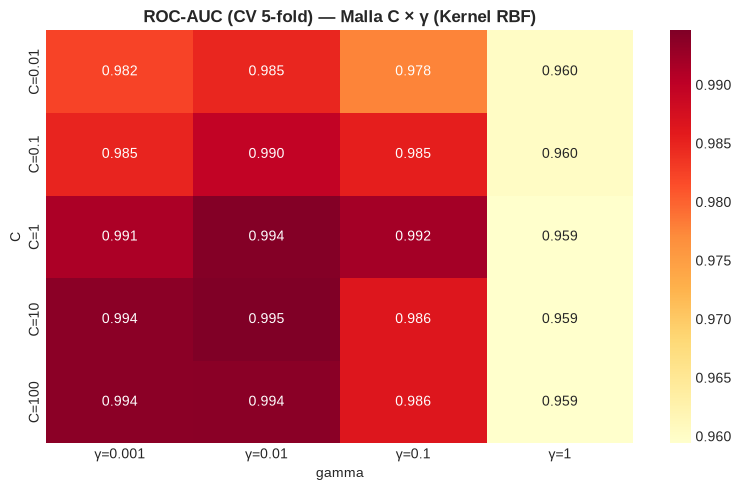

In [6]:
# =============================================================================
# VISUALIZACIÓN: Heatmap de la malla C vs gamma (Validation Accuracy)
# Muestra por qué el grid search en SVM RBF es bidimensional
# =============================================================================
results = grid.cv_results_
scores_grid = results['mean_test_score']

C_list = [0.01, 0.1, 1, 10, 100]
G_list = [0.001, 0.01, 0.1, 1]   # excluimos 'scale' para la visualización

# Submatriz sin 'scale'
scores_matrix = np.array([
    [results['mean_test_score'][i]
     for i, p in enumerate(results['params'])
     if p['svc__C'] == C and p['svc__gamma'] == G]
    for C in C_list
    for G in G_list
]).reshape(len(C_list), len(G_list))

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(scores_matrix, annot=True, fmt='.3f',
            xticklabels=[f'γ={g}' for g in G_list],
            yticklabels=[f'C={c}' for c in C_list],
            cmap='YlOrRd', ax=ax)
ax.set_title('ROC-AUC (CV 5-fold) — Malla C × γ (Kernel RBF)', fontsize=12, fontweight='bold')
ax.set_xlabel('gamma'); ax.set_ylabel('C')
plt.tight_layout()
plt.show()

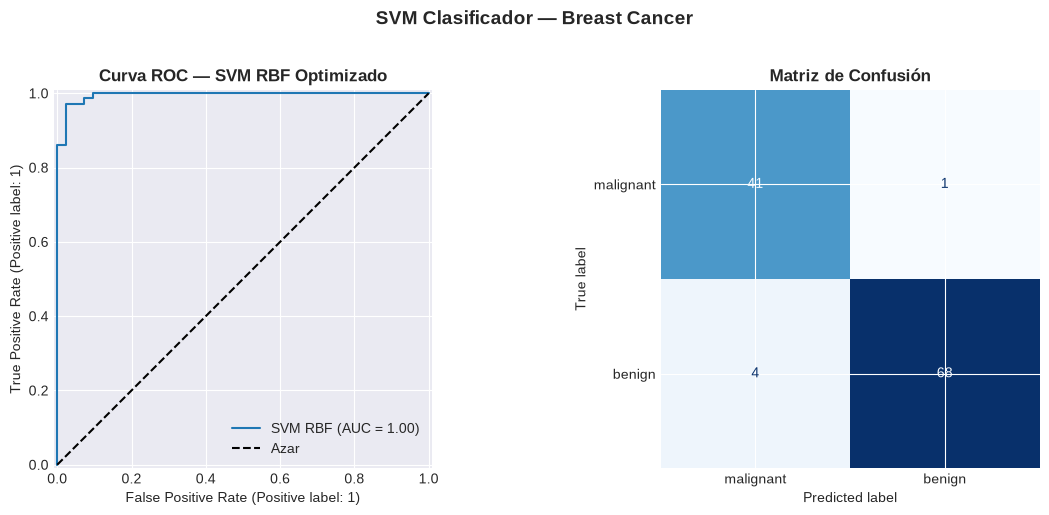

In [7]:
# =============================================================================
# EVALUACIÓN FINAL: ROC + Matriz de Confusión
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_estimator(best_svm, X_te, y_te, ax=axes[0], name='SVM RBF')
axes[0].plot([0,1],[0,1],'k--', label='Azar')
axes[0].set_title('Curva ROC — SVM RBF Optimizado', fontweight='bold')
axes[0].legend()

ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred_gs),
                       display_labels=bc.target_names).plot(
    ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Matriz de Confusión', fontweight='bold')

plt.suptitle('SVM Clasificador — Breast Cancer', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [8]:
# =============================================================================
# LinearSVC: alternativa rápida para datasets grandes
# O(n*d) en lugar de O(n²*d) del SVC tradicional
# =============================================================================
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

linear_svc_pipe = Pipeline([
    ('scaler', StandardScaler()),
    # CalibratedClassifierCV añade probabilidades a LinearSVC (que no las tiene)
    ('svc', CalibratedClassifierCV(LinearSVC(C=1.0, max_iter=5000, random_state=SEED)))
])

cv_scores_lin = cross_val_score(linear_svc_pipe, X_bc, y_bc, cv=5, scoring='roc_auc')
cv_scores_rbf = cross_val_score(pipe_svm, X_bc, y_bc, cv=5, scoring='roc_auc')

print('Comparativa SVC vs LinearSVC:')
print(f'  LinearSVC  ROC-AUC: {cv_scores_lin.mean():.4f} ± {cv_scores_lin.std():.4f}')
print(f'  SVC (RBF)  ROC-AUC: {cv_scores_rbf.mean():.4f} ± {cv_scores_rbf.std():.4f}')

Comparativa SVC vs LinearSVC:
  LinearSVC  ROC-AUC: 0.9906 ± 0.0062
  SVC (RBF)  ROC-AUC: 0.9964 ± 0.0035


---
## 10. Resumen y Checklist

| Aspecto | Detalle |
|---|---|
| **Tipo** | Clasificador de margen máximo |
| **Preprocesamiento** | `StandardScaler` **obligatorio** |
| **Hiperparámetros clave** | `C`, `kernel`, `gamma` (RBF) |
| **Escalabilidad** | Lento: O(n²)~O(n³); usar `LinearSVC` para n > 10k |
| **Probabilidades** | `probability=True` (Platt scaling, lento) |
| **Interpretabilidad** | Baja (kernel no lineal) / Media (lineal: pesos) |

### ✅ Checklist:
- [ ] ¿Escalé con `StandardScaler`? (**CRÍTICO**)
- [ ] ¿Hice GridSearch en malla log de C y γ?
- [ ] ¿Usé `LinearSVC` si n > 50k?
- [ ] ¿Activé `class_weight='balanced'` si hay desbalanceo?
- [ ] ¿Necesito probabilidades? → `probability=True` o `CalibratedClassifierCV`

---
*Ver notebook de regresión: `svm_regressor.ipynb`*